# Experiment 10 - Part 2: Semantic Caching with Redis

**Course:** HAAI302COM - Artificial Intelligence Laboratory

Calling an LLM costs money and about a second. Users ask the same things again and again, often in different words: "How do I reset my password?" and "I forgot my password, how can I change it?". A normal cache keyed on the exact text misses the second one. A **semantic cache** compares the *meaning*: it turns each question into an embedding vector, finds the closest earlier question, and if it is close enough it returns the stored answer without calling the model.

We build one with **Redis** (storage, expiry) and sentence embeddings, and then spend most of the notebook on the hard question: **how close is close enough?** A threshold that is too low returns wrong answers (the answer to "Celsius to Fahrenheit" for "Fahrenheit to Celsius"); one that is too high never hits.

(GPTCache and RedisVL are ready-made libraries for the same idea. We write it ourselves so every step is visible; section 9 shows how the libraries map to it.)

## 0. Setup

Redis runs in a Docker container (`docker run -d --name lab-redis -p 127.0.0.1:6379:6379 redis:7-alpine`). The embedding model is `all-MiniLM-L6-v2`, as in Experiments 4 to 6.

In [1]:
import time, json, hashlib, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import redis
from sentence_transformers import SentenceTransformer

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 170)
r = redis.Redis(host="127.0.0.1", port=6379)
print("redis ping:", r.ping(), "| version:", r.info()["redis_version"])
encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

redis ping: True | version: 7.4.12


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

## 1. Redis in four commands

Redis is an in-memory key-value store. The four things we need: `set`/`get` for a value, `expire` (time to live: the key vanishes by itself), `hset` for a record with several fields, and `incr` for an atomic counter. Everything lives under a **namespace prefix** (`lab:`), so cleaning up is easy.

In [2]:
r.set("lab:greeting", "hello", ex=60)                      # ex = expire after 60 seconds
r.hset("lab:record", mapping={"prompt": "hi", "response": "hello!"})
r.incr("lab:counter"); r.incr("lab:counter")
print("get   :", r.get("lab:greeting"), "| ttl:", r.ttl("lab:greeting"), "s")
print("hgetall:", r.hgetall("lab:record"), "| counter:", r.get("lab:counter"))
r.delete("lab:greeting", "lab:record", "lab:counter")

get   : b'hello' | ttl: 60 s
hgetall: {b'prompt': b'hi', b'response': b'hello!'} | counter: b'2'


3

**What to notice:** Redis returns bytes (b'hello') unless you ask for decoded strings, so our class decodes where needed. The TTL counts down on its own (60 s), a hash holds several fields, and incr is atomic: two clients incrementing at the same time never lose a count. That atomic counter is what makes rate limiting and hit statistics safe.

## 2. The test traffic: paraphrases and look-alikes

To measure a cache we need questions where we know which ones mean the same thing. We wrote 12 *groups* of 4 paraphrases each (same meaning, different words) and 4 **hard-negative groups**: questions whose wording is almost the same as another group but whose answer is different ("capital of Germany" next to "capital of France"; "Fahrenheit to Celsius" next to "Celsius to Fahrenheit"). A good cache hits within a group and never across groups.

In [3]:
%%writefile traffic.py
GROUPS = {
 "capital_fr": ["What is the capital of France?", "Which city is the capital of France?", "Tell me the capital city of France", "France's capital is what?"],
 "pw_reset": ["How do I reset my password?", "I forgot my password, how can I change it?", "Steps to recover my account password", "Password reset instructions please"],
 "egg_boil": ["How long should I boil an egg?", "What is the boiling time for eggs?", "How many minutes to cook a hard boiled egg?", "Time needed to boil eggs"],
 "py_list_tuple": ["What is the difference between a list and a tuple in Python?", "Python lists vs tuples: how do they differ?", "How is a tuple different from a list in Python?", "Explain list versus tuple in Python"],
 "photosynthesis": ["What is photosynthesis?", "Explain how photosynthesis works", "Can you describe the process of photosynthesis?", "How do plants make food from sunlight?"],
 "refund": ["What is your refund policy?", "How can I get my money back?", "Do you offer refunds?", "Tell me about returning a product for a refund"],
 "c_to_f": ["How do I convert Celsius to Fahrenheit?", "Formula to change Celsius into Fahrenheit", "Convert degrees Celsius to degrees Fahrenheit", "What is the Celsius to Fahrenheit conversion?"],
 "rag": ["What is retrieval augmented generation?", "Explain RAG in simple terms", "How does retrieval-augmented generation work?", "What does RAG mean in AI?"],
 "tallest": ["What is the tallest mountain in the world?", "Which mountain is the highest on Earth?", "Name the world's tallest mountain", "Highest mountain on the planet?"],
 "str_reverse": ["How do I reverse a string in Python?", "Python code to reverse a string", "What is the way to reverse text in Python?", "Reverse a string using Python"],
 "overfitting": ["What is overfitting in machine learning?", "Explain overfitting", "What does it mean when a model overfits?", "Describe overfitting in ML"],
 "learn_py": ["How can I learn Python quickly?", "Best way to learn Python fast", "Tips for learning Python in a short time", "What is the fastest way to get good at Python?"],
}
HARD = {
 "capital_de": ["What is the capital of Germany?", "Which city is the capital of Germany?"],
 "router_reset": ["How do I reset my router?", "Steps to reset my wifi router"],
 "egg_fry": ["How long should I fry an egg?", "What is the frying time for eggs?"],
 "f_to_c": ["How do I convert Fahrenheit to Celsius?", "Formula to change Fahrenheit into Celsius"],
}

Overwriting traffic.py


In [4]:
from traffic import GROUPS, HARD
rows = [(q, g) for g, qs in {**GROUPS, **HARD}.items() for q in qs]
traffic = pd.DataFrame(rows, columns=["query", "group"]).sample(frac=1, random_state=3).reset_index(drop=True)
print(len(traffic), "queries,", traffic.group.nunique(), "groups;", len(traffic) - traffic.group.nunique(), "of them are repeats of an earlier meaning")
traffic.head(6)

56 queries, 16 groups; 40 of them are repeats of an earlier meaning


,query,group
0,What is the difference between a list and a tuple in Python?,py_list_tuple
1,Name the world's tallest mountain,tallest
2,What is the boiling time for eggs?,egg_boil
3,What is the frying time for eggs?,egg_fry
4,Tips for learning Python in a short time,learn_py
5,Formula to change Fahrenheit into Celsius,f_to_c


## 3. Baseline: an exact-match cache

The simplest cache normalises the text (lowercase, trim) and uses its hash as the Redis key. We replay the traffic: on a miss we "call the model" and store; on a hit we return the stored value. A hit is **correct** if the stored answer belongs to the same group.

In [5]:
def norm(t): return " ".join(t.lower().split())
def exact_key(t): return "lab:exact:" + hashlib.sha256(norm(t).encode()).hexdigest()[:16]

hits = correct = 0
for q, g in zip(traffic["query"], traffic.group):
    got = r.get(exact_key(q))
    if got is not None:
        hits += 1; correct += got.decode() == g
    else:
        r.set(exact_key(q), g, ex=300)
for q, g in zip(traffic["query"], traffic.group):                   # replay the SAME traffic a second time
    got = r.get(exact_key(q)); hits += got is not None
print("first pass hits:", hits - len(traffic), "of", len(traffic), "| second pass hits:", len(traffic), "of", len(traffic))
for k in r.scan_iter("lab:exact:*"): r.delete(k)

first pass hits: 0 of 56 | second pass hits: 56 of 56


**What to notice:** the exact cache found 0 hits in the first pass, although 40 of the 56 queries repeat the meaning of an earlier one: a different wording gives a different hash. Only when the identical texts were replayed did it hit every time (56 of 56). An exact cache is right for repeated identical requests and blind to paraphrases.

## 4. Embeddings: how similar are paraphrases and look-alikes?

`encoder.encode(..., normalize_embeddings=True)` returns unit vectors, so the dot product of two vectors is their **cosine similarity** (1.0 = same direction, 0 = unrelated). We compare a base question with a paraphrase, with a hard negative that looks similar but means something else, and with an unrelated question.

In [6]:
def sim(a, b):
    va, vb = encoder.encode([a, b], normalize_embeddings=True)
    return float(va @ vb)

pairs = [("paraphrase", "What is the capital of France?", "Which city is the capital of France?"),
         ("paraphrase", "How do I reset my password?", "I forgot my password, how can I change it?"),
         ("hard negative", "What is the capital of France?", "What is the capital of Germany?"),
         ("hard negative", "How do I convert Celsius to Fahrenheit?", "How do I convert Fahrenheit to Celsius?"),
         ("hard negative", "How do I reset my password?", "How do I reset my router?"),
         ("unrelated", "What is the capital of France?", "How do I reverse a string in Python?")]
pd.DataFrame([dict(kind=k, a=a[:42], b=b[:42], cosine=sim(a, b)) for k, a, b in pairs]).round(3)

,kind,a,b,cosine
0,paraphrase,What is the capital of France?,Which city is the capital of France?,0.942
1,paraphrase,How do I reset my password?,"I forgot my password, how can I change it?",0.894
2,hard negative,What is the capital of France?,What is the capital of Germany?,0.663
3,hard negative,How do I convert Celsius to Fahrenheit?,How do I convert Fahrenheit to Celsius?,0.995
4,hard negative,How do I reset my password?,How do I reset my router?,0.530
5,unrelated,What is the capital of France?,How do I reverse a string in Python?,0.138


**What to notice:** paraphrases score 0.94 and 0.89, the hard negatives about a different place or device score clearly lower (0.66 for Germany, 0.53 for router), and unrelated questions are near 0.14. But the Celsius to Fahrenheit and Fahrenheit to Celsius pair scores 0.995, higher than either paraphrase pair. The embedding captures the topic (temperature conversion) and ignores the direction. Word order, negation and direction are what sentence embeddings blur, so a threshold alone cannot separate such pairs.

## 5. Choosing the threshold

The cache returns a stored answer when the best similarity is at least the threshold. We replay the 56 queries against an in-memory cache for thresholds from 0.50 to 0.95 and count, for each:

- **hit rate**: share of queries answered from the cache;
- **wrong hits**: hits where the stored answer belongs to a *different* group (a wrong answer sent to a user);
- **recall**: correct hits divided by the 40 hits that were possible (every query that repeats an earlier meaning).

In [7]:
E = encoder.encode(list(traffic["query"]), normalize_embeddings=True)
groups = list(traffic.group)
POSSIBLE = len(traffic) - traffic.group.nunique()

def replay(threshold):
    store_vecs, store_groups, ok, bad = [], [], 0, 0
    for v, g in zip(E, groups):
        if store_vecs:
            s = np.array(store_vecs) @ v
            j = int(s.argmax())
            if s[j] >= threshold:
                ok += store_groups[j] == g; bad += store_groups[j] != g
                continue                                   # hit: nothing is stored
        store_vecs.append(v); store_groups.append(g)       # miss: call the model, store the answer
    return ok, bad

sweep = pd.DataFrame([dict(threshold=t, correct_hits=replay(t)[0], wrong_hits=replay(t)[1]) for t in np.arange(0.50, 0.96, 0.05).round(2)])
sweep["hit_rate"] = (sweep.correct_hits + sweep.wrong_hits) / len(traffic)
sweep["recall"] = sweep.correct_hits / POSSIBLE
sweep.round(3)

,threshold,correct_hits,wrong_hits,hit_rate,recall
0,0.50,32,10,0.750,0.800
1,0.55,31,9,0.714,0.775
2,0.60,31,7,0.679,0.775
3,0.65,31,5,0.643,0.775
4,0.70,30,5,0.625,0.750
5,0.75,27,5,0.571,0.675
6,0.80,25,4,0.518,0.625
7,0.85,24,1,0.446,0.600
8,0.90,11,4,0.268,0.275
9,0.95,5,2,0.125,0.125


**What to notice:** recall falls from 0.80 at a threshold of 0.50 to 0.60 at 0.85, then drops to 0.275 at 0.90 and 0.125 at 0.95: the paraphrases in this set score between about 0.85 and 0.94, so a threshold of 0.90 throws half of the real hits away. Wrong hits fall from 10 at 0.50 to 1 at 0.85, but then rise again to 4 at 0.90, and they never reach zero. The reason is that, with a high threshold, paraphrases miss and are stored as separate entries, so later queries meet more near-duplicates, including the direction-swapped pair that scores 0.995, above every threshold we tried.

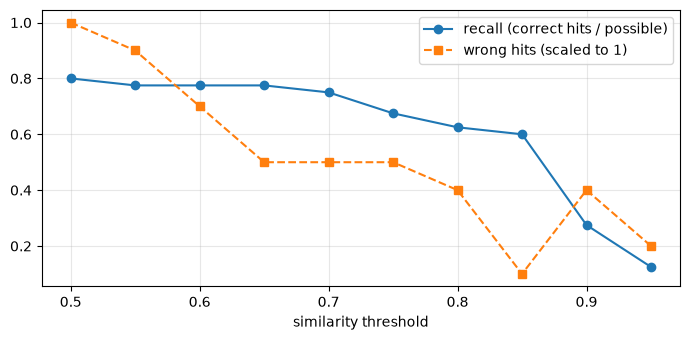

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(sweep.threshold, sweep.recall, "o-", label="recall (correct hits / possible)")
ax.plot(sweep.threshold, sweep.wrong_hits / sweep.wrong_hits.max().clip(1), "s--", label="wrong hits (scaled to 1)")
ax.set_xlabel("similarity threshold"); ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

In [9]:
# a wrong answer is judged three times as bad as a correct hit is good; pick the threshold with the best score
WRONG_COST = 3
sweep["utility"] = sweep.correct_hits - WRONG_COST * sweep.wrong_hits
CHOSEN = float(sweep.loc[sweep.utility.idxmax(), "threshold"])
open("chosen_threshold.txt", "w").write(str(CHOSEN))          # notebook 03 reads this value
print("chosen threshold:", CHOSEN, "| recall:", round(float(sweep[sweep.threshold == CHOSEN].recall.iloc[0]), 3),
      "| wrong hits:", int(sweep[sweep.threshold == CHOSEN].wrong_hits.iloc[0]))
sweep[["threshold", "correct_hits", "wrong_hits", "utility"]].T

chosen threshold: 0.85 | recall: 0.6 | wrong hits: 1


,0,1,2,3,4,5,6,7,8,9
threshold,0.5,0.55,0.6,0.65,0.7,0.75,0.8,0.85,0.9,0.95
correct_hits,32.0,31.00,31.0,31.00,30.0,27.00,25.0,24.00,11.0,5.00
wrong_hits,10.0,9.00,7.0,5.00,5.0,5.00,4.0,1.00,4.0,2.00
utility,2.0,4.00,10.0,16.00,15.0,12.00,13.0,21.00,-1.0,-1.00


**What to notice:** we cannot demand zero wrong hits, so we put a price on them: a wrong answer counts as three lost hits. The best score is at 0.85, with 24 correct hits, 1 wrong hit and a recall of 0.60. The wrong hit is exactly the direction problem from section 4: someone asking for Celsius into Fahrenheit received the answer for Fahrenheit into Celsius. A threshold cannot fix it; options are a second check on every hit (a cross-encoder or a small LLM asked whether the two questions are equivalent), rules for words such as 'to', 'from' and 'not', or accepting the risk for low-stakes answers. The value 0.85 also belongs to this model and this data: tune it on your own traffic.

Which queries got a wrong answer at the chosen threshold? We list each wrong hit with the cached question whose answer it received.

In [10]:
def wrong_hits(threshold):
    vecs, qs, gs, out = [], [], [], []
    for q, v, g in zip(traffic["query"], E, groups):
        if vecs:
            s = np.array(vecs) @ v; j = int(s.argmax())
            if s[j] >= threshold:
                if gs[j] != g: out.append(dict(query=q[:46], got_answer_of=qs[j][:46], score=round(float(s[j]), 3)))
                continue
        vecs.append(v); qs.append(q); gs.append(g)
    return pd.DataFrame(out)
wrong_hits(CHOSEN)

,query,got_answer_of,score
0,Formula to change Celsius into Fahrenheit,Formula to change Fahrenheit into Celsius,0.996


## 6. The cache class

`SemanticCache` stores each entry as a Redis **hash** (`prompt`, `response`, the embedding as raw bytes `vec`, a timestamp) with a TTL, and keeps the entry ids in a **set**. `lookup` fetches all vectors in one pipelined round trip, computes the dot products with NumPy and returns the best match above the threshold. Hits and misses are counted with `incr`. A `namespace` lets us keep several caches (per model, per prompt version, per tenant) in one Redis. The file is written to `semcache.py` and imported by the service in notebook 03.

In [11]:
%%writefile semcache.py
import time, uuid
import numpy as np


class SemanticCache:
    def __init__(self, redis_client, encoder, threshold=0.85, ttl=3600, namespace="chat:v1"):
        self.r, self.encoder, self.threshold, self.ttl, self.ns = redis_client, encoder, threshold, ttl, namespace

    def embed(self, text):
        return self.encoder.encode([text], normalize_embeddings=True)[0].astype("float32")

    def lookup(self, prompt, vec=None):
        # returns (response or None, best_score, entry_id or None)
        vec = self.embed(prompt) if vec is None else vec
        ids = [i.decode() for i in self.r.smembers(f"{self.ns}:ids")]
        if not ids:
            self.r.incr(f"{self.ns}:stat:misses")
            return None, 0.0, None
        pipe = self.r.pipeline()
        for i in ids:
            pipe.hget(f"{self.ns}:e:{i}", "vec")
        vecs = pipe.execute()
        alive = [(i, np.frombuffer(v, dtype="float32")) for i, v in zip(ids, vecs) if v is not None]
        dead = [i for i, v in zip(ids, vecs) if v is None]            # entries whose TTL has run out
        if dead:
            self.r.srem(f"{self.ns}:ids", *dead)
        best, best_id = 0.0, None
        if alive:
            scores = np.stack([v for _, v in alive]) @ vec
            j = int(scores.argmax()); best, best_id = float(scores[j]), alive[j][0]
        if best_id is not None and best >= self.threshold:
            resp = self.r.hget(f"{self.ns}:e:{best_id}", "response")
            if resp is not None:
                self.r.incr(f"{self.ns}:stat:hits")
                return resp.decode(), best, best_id
        self.r.incr(f"{self.ns}:stat:misses")
        return None, best, None

    def store(self, prompt, response, vec=None, ttl=None):
        vec = self.embed(prompt) if vec is None else vec
        i = uuid.uuid4().hex[:12]
        key = f"{self.ns}:e:{i}"
        self.r.hset(key, mapping={"prompt": prompt, "response": response, "vec": vec.tobytes(), "ts": time.time()})
        self.r.expire(key, ttl or self.ttl)
        self.r.sadd(f"{self.ns}:ids", i)
        return i

    def stats(self):
        h = int(self.r.get(f"{self.ns}:stat:hits") or 0); m = int(self.r.get(f"{self.ns}:stat:misses") or 0)
        return {"hits": h, "misses": m, "hit_rate": round(h / (h + m), 3) if h + m else 0.0, "entries": self.r.scard(f"{self.ns}:ids")}

    def clear(self):
        for k in self.r.scan_iter(f"{self.ns}:*"):
            self.r.delete(k)

Overwriting semcache.py


We replay the same 56 queries through the **Redis-backed** class at the chosen threshold. The result should agree with the in-memory simulation.

In [12]:
from semcache import SemanticCache
cache = SemanticCache(r, encoder, threshold=CHOSEN, ttl=600, namespace="lab:cache")
cache.clear()
ok = bad = 0
for q, g, v in zip(traffic["query"], traffic.group, E):
    resp, score, _ = cache.lookup(q, vec=v)
    if resp is None:
        cache.store(q, g, vec=v)                       # the 'answer' is just the group label in this test
    else:
        ok += resp == g; bad += resp != g
print("Redis cache -> correct hits:", ok, "| wrong hits:", bad, "| in-memory simulation:", replay(CHOSEN))
print(cache.stats())

Redis cache -> correct hits: 24 | wrong hits: 1 | in-memory simulation: (24, 1)
{'hits': 25, 'misses': 31, 'hit_rate': 0.446, 'entries': 31}


**What to notice:** the Redis-backed class gives the same numbers as the in-memory simulation (24 correct hits, 1 wrong hit), which confirms that the storage layer does not change the behaviour. The counters report 25 hits and 31 misses (hit rate 0.446) and 31 stored entries: each miss stored one entry, and hits stored nothing.

## 7. Cost of a lookup, and why a vector index matters

Our `lookup` reads **every** vector from Redis and compares them in NumPy: simple, but the work grows with the number of entries. We measure the time of one lookup as the cache grows (extra entries are random unit vectors).

In [13]:
rng = np.random.default_rng(0)
big = SemanticCache(r, encoder, threshold=CHOSEN, ttl=600, namespace="lab:big"); big.clear()
q_vec = E[0]; rows = []; n_have = 0
for target in [10, 100, 1000, 5000]:
    pipe = r.pipeline()
    for _ in range(target - n_have):
        v = rng.normal(size=384).astype("float32"); v /= np.linalg.norm(v)
        i = f"x{n_have}"; n_have += 1
        pipe.hset(f"lab:big:e:{i}", mapping={"prompt": "x", "response": "x", "vec": v.tobytes()}); pipe.expire(f"lab:big:e:{i}", 600); pipe.sadd("lab:big:ids", i)
    pipe.execute()
    t = time.time(); [big.lookup("q", vec=q_vec) for _ in range(5)]
    rows.append(dict(entries=target, lookup_ms=(time.time() - t) / 5 * 1000))
big.clear()
pd.DataFrame(rows).round(1)

,entries,lookup_ms
0,10,0.9
1,100,3.2
2,1000,23.4
3,5000,143.8


**What to notice:** one lookup takes 0.9 ms with 10 entries, 3 ms with 100, 23 ms with 1,000 and 144 ms with 5,000. It grows in proportion to the number of entries because we fetch and compare every vector. Up to a few hundred entries this is negligible beside a one-second model call; at 5,000 entries the lookup alone costs 14 percent of a call. Beyond that, move the search into a vector index (RediSearch with HNSW, or Qdrant from Experiment 6).

## 8. Expiry, versioning and safety

**TTL.** Facts go stale. Every entry expires after `ttl` seconds, and Redis removes it by itself. We store with a 2 second TTL to see it disappear.

**Namespaces.** If you change the model or the system prompt, old cached answers are no longer valid. Putting a version in the namespace (`chat:v1` to `chat:v2`) starts a clean cache without deleting anything.

In [14]:
t = SemanticCache(r, encoder, threshold=0.8, ttl=2, namespace="lab:ttl"); t.clear()
t.store("What is the capital of France?", "Paris")
print("immediately :", t.lookup("Which city is the capital of France?")[:2])
time.sleep(3)
print("after 3 s   :", t.lookup("Which city is the capital of France?")[:2])
v2 = SemanticCache(r, encoder, threshold=0.8, ttl=60, namespace="lab:ttl:v2")
print("new version :", v2.lookup("What is the capital of France?")[:2]); t.clear(); v2.clear()

immediately : ('Paris', 0.9416358470916748)


after 3 s   : (None, 0.0)
new version : (None, 0.0)


**What to notice:** right after storing, the paraphrase hits the entry (answer 'Paris', similarity 0.94). After 3 seconds the 2 second TTL has expired: Redis deleted the entry by itself and the lookup returns a miss. A new namespace (v2) starts empty, which is the cheap way to invalidate a whole cache when the model or the prompt changes.

**Safety rules for a semantic cache** (no code, but you must know them):

- Never cache answers that depend on the **user** (their account, location, history) unless the user or tenant id is part of the namespace; otherwise one user can receive another's answer.
- Do not cache **time-sensitive** questions ("what is the weather now") or use a very short TTL.
- Do not cache when the request has a different `temperature`, `max_tokens` or system prompt; include those in the namespace or skip the cache.
- Log the similarity score of every hit so that you can audit wrong hits later.

## 9. The same idea with libraries

- **RedisVL** `SemanticCache(name=..., distance_threshold=..., redis_url=...)` stores vectors in a RediSearch index (needs the `redis-stack` image) and does the nearest-neighbour search inside Redis, so lookup stays fast with millions of entries. Its `distance_threshold` is a cosine *distance*, that is, 1 minus our similarity.
- **GPTCache** wraps the OpenAI client and adds an embedding function, a vector store and a similarity evaluator; its default threshold plays the role of our `CHOSEN`.

The decisions you make are the same in all of them: the embedding model, the threshold, the TTL and the namespace.

## 10. Cleaning up and recap

In [15]:
n = 0
for k in r.scan_iter("lab:*"):
    r.delete(k); n += 1
print("deleted", n, "lab keys; remaining keys:", r.dbsize())

deleted 34 lab keys; remaining keys: 0


- An exact cache only helps repeats; a semantic cache also catches paraphrases.
- The threshold is the whole game: measure hit rate and **wrong hits** on traffic that includes hard negatives, and pick the threshold with the best trade-off.
- Redis gives storage, expiry and counters; scale needs a vector index.
- Namespace by model, prompt version and user; keep TTLs short for facts that change.

**Try yourself:** (1) add 5 more hard negatives of your own and re-run the sweep; (2) try `all-mpnet-base-v2` as the encoder; (3) store the embedding as `float16` and compare memory.

Next: **Notebook 03** puts the cache inside the service, adds request logging and tracing, and load-tests it.